<a href="https://colab.research.google.com/github/VSBhuvana/Machine-Learning-LAB-sessions/blob/main/ML_LAB_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# A1 - AI Tool Used: ChatGPT

import pandas as pd
import numpy as np
from collections import Counter


cols = [
    "Class",
    "Alcohol",
    "Malicacid",
    "Ash",
    "Alcalinity_of_ash",
    "Magnesium",
    "Total_phenols",
    "Flavanoids",
    "Nonflavanoid_phenols",
    "Proanthocyanins",
    "Color_intensity",
    "Hue",
    "OD280_OD315",
    "Proline"
]


def distance(a, b):

    return np.linalg.norm(
        np.array(a) - np.array(b)
    )


def merge_sort(arr):

    if len(arr) <= 1:
        return arr

    middle = len(arr) // 2

    left = merge_sort(arr[:middle])
    right = merge_sort(arr[middle:])

    result = []

    i = 0
    j = 0

    while i < len(left) and j < len(right):

        if left[i][0] <= right[j][0]:

            result.append(left[i])
            i += 1

        else:

            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


def quick_sort(arr):

    if len(arr) <= 1:
        return arr

    pivot = arr[-1][0]

    left = []
    middle = []
    right = []

    for item in arr:

        if item[0] < pivot:
            left.append(item)

        elif item[0] == pivot:
            middle.append(item)

        else:
            right.append(item)

    return (
        quick_sort(left)
        + middle
        + quick_sort(right)
    )


def heapify(arr, n, i):

    largest = i

    left = 2 * i + 1
    right = 2 * i + 2

    if left < n and arr[left][0] > arr[largest][0]:
        largest = left

    if right < n and arr[right][0] > arr[largest][0]:
        largest = right

    if largest != i:

        arr[i], arr[largest] = (
            arr[largest],
            arr[i]
        )

        heapify(arr, n, largest)


def heap_sort(arr):

    arr = arr.copy()

    n = len(arr)

    for i in range(n // 2 - 1, -1, -1):

        heapify(arr, n, i)

    for i in range(n - 1, 0, -1):

        arr[0], arr[i] = (
            arr[i],
            arr[0]
        )

        heapify(arr, i, 0)

    return arr


def sort_neighbors(arr, algorithm):

    if algorithm == "merge":

        return merge_sort(arr)

    elif algorithm == "quick":

        return quick_sort(arr)

    elif algorithm == "heap":

        return heap_sort(arr)

    else:

        return merge_sort(arr)


def find_neighbors(train_data, test_point):

    train_array = np.array(train_data)

    labels = train_array[:, 0]

    features = train_array[:, 1:].astype(float)

    test_point = np.array(
        test_point,
        dtype=float
    )

    distances = np.linalg.norm(
        features - test_point,
        axis=1
    )

    neighbors = []

    for i in range(len(distances)):

        neighbors.append(
            [distances[i], labels[i]]
        )

    return neighbors


def k_nearest_neighbors(
    neighbors,
    k,
    algorithm
):

    sorted_neighbors = sort_neighbors(
        neighbors,
        algorithm
    )

    return sorted_neighbors[:k]


def predict_class(neighbors):

    labels = []

    for neighbor in neighbors:

        labels.append(neighbor[1])

    counts = Counter(labels)

    highest_count = max(
        counts.values()
    )

    tied_labels = []

    for label in counts:

        if counts[label] == highest_count:

            tied_labels.append(label)

    if len(tied_labels) == 1:

        return tied_labels[0]

    for neighbor in neighbors:

        if neighbor[1] in tied_labels:

            return neighbor[1]


df = pd.read_csv(
    "wine.data",
    header=None,
    names=cols
)


data = df.values.tolist()

train_data = data[:150]

test_data = data[150:]


k = 5

sorting_algorithm = "merge"


print("A1 - AI Assisted kNN")

print(
    "Sorting Algorithm =",
    sorting_algorithm
)

print(
    "k =",
    k
)

print()


for i in range(len(test_data)):

    test_row = test_data[i]

    actual_class = test_row[0]

    test_point = test_row[1:]


    neighbors = find_neighbors(
        train_data,
        test_point
    )


    k_neighbors = k_nearest_neighbors(
        neighbors,
        k,
        sorting_algorithm
    )


    prediction = predict_class(
        k_neighbors
    )


    print(
        "Test Point =", i + 1,
        "Actual Class =", actual_class,
        "Predicted Class =", prediction
    )

A1 - AI Assisted kNN
Sorting Algorithm = merge
k = 5

Test Point = 1 Actual Class = 3.0 Predicted Class = 3.0
Test Point = 2 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 3 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 4 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 5 Actual Class = 3.0 Predicted Class = 3.0
Test Point = 6 Actual Class = 3.0 Predicted Class = 3.0
Test Point = 7 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 8 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 9 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 10 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 11 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 12 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 13 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 14 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 15 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 16 Actual Class = 3.0 Predicted Class = 2.0
Test Point = 17 Actual Class = 3.0 Predicte

In [ ]:
# A2 - AI Tool Used: ChatGPT

from collections import defaultdict


def weighted_vote(neighbors):

    weights = defaultdict(float)

    for distance_value, label in neighbors:

        if distance_value == 0:
            weights[label] += float("inf")
        else:
            weights[label] += 1 / distance_value

    highest_weight = max(weights.values())

    tied_labels = [
        label
        for label in weights
        if weights[label] == highest_weight
    ]

    if len(tied_labels) == 1:
        return tied_labels[0]

    for distance_value, label in neighbors:

        if label in tied_labels:
            return label


neighbors = [
    [0.5, 1],
    [1.0, 2],
    [2.0, 2]
]

prediction = weighted_vote(neighbors)

print("A2 - WEIGHTED kNN")

print("Weighted kNN Prediction =", prediction)

A2 - WEIGHTED kNN
Weighted kNN Prediction = 1


In [ ]:
# A3 - AI Tool Used: ChatGPT

import pandas as pd
from sklearn.model_selection import train_test_split


def prepare_data(data_frame):

    data = data_frame.values.tolist()

    selected_data = []

    for row in data:

        if row[0] == 1 or row[0] == 2:

            selected_data.append(row)

    X = []
    y = []

    for row in selected_data:

        y.append(row[0])

        X.append(row[1:])

    return X, y


def split_data(X, y):

    return train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=42
    )


data_frame = pd.read_csv("wine.csv")

X, y = prepare_data(data_frame)

X_train, X_test, y_train, y_test = split_data(X, y)


print("A3 - TRAIN / TEST SPLIT")

print("Total Samples =", len(X))

print("Training Samples =", len(X_train))

print("Testing Samples =", len(X_test))

print()

print("Training Labels =")
print(y_train)

print()

print("Testing Labels =")
print(y_test)


A3 - TRAIN / TEST SPLIT
Total Samples = 130
Training Samples = 91
Testing Samples = 39

Training Labels =
[1.0, 1.0, 2.0, 2.0, 1.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0, 1.0, 2.0, 2.0, 1.0, 1.0, 2.0, 2.0, 1.0, 1.0, 1.0, 1.0, 2.0, 1.0, 2.0, 1.0, 1.0, 2.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 1.0, 1.0, 2.0, 2.0, 1.0, 2.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0, 2.0, 1.0, 2.0, 1.0, 2.0, 2.0, 2.0, 2.0, 1.0, 1.0, 2.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 1.0, 2.0, 2.0, 2.0, 1.0, 2.0, 2.0]

Testing Labels =
[1.0, 1.0, 1.0, 1.0, 2.0, 1.0, 2.0, 2.0, 2.0, 1.0, 2.0, 1.0, 2.0, 1.0, 2.0, 2.0, 1.0, 2.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0, 1.0, 2.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 2.0, 2.0, 1.0, 2.0]


In [ ]:
# A4 - AI Tool Used: ChatGPT

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


def prepare_data(data_frame):

    selected_data = data_frame[
        data_frame["Class"].isin([1, 2])
    ]

    X = selected_data.drop(
        columns=["Class"]
    )

    y = selected_data["Class"]

    return X, y


def train_knn(X_train, y_train, k):

    model = KNeighborsClassifier(
        n_neighbors=k,
        algorithm="auto"
    )

    model.fit(
        X_train,
        y_train
    )

    return model


df = pd.read_csv("wine.csv")

X, y = prepare_data(df)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

neigh = train_knn(
    X_train,
    y_train,
    3
)


print("A4 - TRAIN kNN WITH k = 3")

print("kNN classifier trained successfully.")

print("Value of k =", 3)

print("Training samples =", len(X_train))

print("Testing samples =", len(X_test))

A4 - TRAIN kNN WITH k = 3
kNN classifier trained successfully.
Value of k = 3
Training samples = 91
Testing samples = 39


In [ ]:
# A5 - AI Tool Used: ChatGPT

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


def calculate_accuracy(model, X_test, y_test):

    return model.score(
        X_test,
        y_test
    )


data_frame = pd.read_csv("wine.csv")

data = data_frame.values.tolist()

selected_data = []

for row in data:

    if row[0] == 1 or row[0] == 2:

        selected_data.append(row)


X = []
y = []

for row in selected_data:

    y.append(row[0])
    X.append(row[1:])


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


neigh = KNeighborsClassifier(
    n_neighbors=3
)

neigh.fit(
    X_train,
    y_train
)


accuracy = calculate_accuracy(
    neigh,
    X_test,
    y_test
)


print("A5 - TEST ACCURACY")

print("k =", 3)

print("Accuracy =", accuracy)

print(
    "Accuracy Percentage =",
    accuracy * 100,
    "%"
)

A5 - TEST ACCURACY
k = 3
Accuracy = 0.8974358974358975
Accuracy Percentage = 89.74358974358975 %


In [ ]:
# A6 - AI Tool Used: ChatGPT

def predict_test_vectors(model, X_test):

    return model.predict(X_test)


predictions = predict_test_vectors(
    neigh,
    X_test
)


print("A6 - PREDICT TEST VECTORS")

for i in range(len(X_test)):

    print(
        "Test Point =", i + 1,
        "Actual Class =", y_test.iloc[i],
        "Predicted Class =", predictions[i]
    )

A6 - PREDICT TEST VECTORS
Test Point = 1 Actual Class = 1 Predicted Class = 1
Test Point = 2 Actual Class = 1 Predicted Class = 1
Test Point = 3 Actual Class = 1 Predicted Class = 1
Test Point = 4 Actual Class = 1 Predicted Class = 1
Test Point = 5 Actual Class = 2 Predicted Class = 2
Test Point = 6 Actual Class = 1 Predicted Class = 1
Test Point = 7 Actual Class = 2 Predicted Class = 1
Test Point = 8 Actual Class = 2 Predicted Class = 2
Test Point = 9 Actual Class = 2 Predicted Class = 2
Test Point = 10 Actual Class = 1 Predicted Class = 1
Test Point = 11 Actual Class = 2 Predicted Class = 1
Test Point = 12 Actual Class = 1 Predicted Class = 1
Test Point = 13 Actual Class = 2 Predicted Class = 2
Test Point = 14 Actual Class = 1 Predicted Class = 1
Test Point = 15 Actual Class = 2 Predicted Class = 2
Test Point = 16 Actual Class = 2 Predicted Class = 2
Test Point = 17 Actual Class = 1 Predicted Class = 1
Test Point = 18 Actual Class = 2 Predicted Class = 2
Test Point = 19 Actual Class 

In [ ]:
# A7 - AI Tool Used: ChatGPT

import numpy as np
from collections import Counter


def distance(a, b):

    return np.linalg.norm(
        np.array(a) - np.array(b)
    )


def find_neighbors(
    training_features,
    training_labels,
    test_point
):

    training_features = np.array(
        training_features,
        dtype=float
    )

    test_point = np.array(
        test_point,
        dtype=float
    )

    distances = np.linalg.norm(
        training_features - test_point,
        axis=1
    )

    neighbors = []

    for i in range(len(distances)):

        neighbors.append(
            [
                distances[i],
                training_labels[i]
            ]
        )

    return neighbors


def predict_class(neighbors):

    labels = []

    for neighbor in neighbors:

        labels.append(neighbor[1])

    counts = Counter(labels)

    highest_count = max(
        counts.values()
    )

    tied_labels = []

    for label in counts:

        if counts[label] == highest_count:

            tied_labels.append(label)

    if len(tied_labels) == 1:

        return tied_labels[0]

    for neighbor in neighbors:

        if neighbor[1] in tied_labels:

            return neighbor[1]


def fit(
    training_features,
    training_labels,
    k
):

    model = [
        training_features,
        training_labels,
        k
    ]

    return model


def predict(
    model,
    test_features
):

    training_features = model[0]

    training_labels = model[1]

    k = model[2]

    predictions = []

    for test_point in test_features:

        neighbors = find_neighbors(
            training_features,
            training_labels,
            test_point
        )

        neighbors.sort(
            key=lambda x: x[0]
        )

        k_neighbors = neighbors[:k]

        prediction = predict_class(
            k_neighbors
        )

        predictions.append(
            prediction
        )

    return predictions


def score(
    model,
    test_features,
    actual_labels
):

    predictions = predict(
        model,
        test_features
    )

    accuracy = np.mean(
        np.array(predictions) ==
        np.array(actual_labels)
    )

    return accuracy


training_features = [
    [1.0, 2.0],
    [1.2, 1.8],
    [5.0, 6.0],
    [5.2, 5.8]
]

training_labels = [
    1, 1, 2, 2
]

test_features = [
    [1.1, 2.1],
    [5.1, 6.1]
]

test_labels = [
    1, 2
]


model = fit(
    training_features,
    training_labels,
    k=3
)


predictions = predict(
    model,
    test_features
)


accuracy = score(
    model,
    test_features,
    test_labels
)


print("A7")

print(
    "Predictions =",
    predictions
)

print(
    "Actual Labels =",
    test_labels
)

print(
    "Accuracy =",
    accuracy
)

A7
Predictions = [1, 2]
Actual Labels = [1, 2]
Accuracy = 1.0


A8 - CUSTOM kNN vs PACKAGE kNN

k = 1 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 2 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 3 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 4 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 5 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 6 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 7 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 8 Custom = 0.8717948717948718 Package = 0.8974358974358975
k = 9 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 10 Custom = 0.8974358974358975 Package = 0.8974358974358975
k = 11 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 12 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 13 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 14 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 15 Custom = 0.9230769230769231 Package = 0.9230769230769231
k = 16 Custom = 0

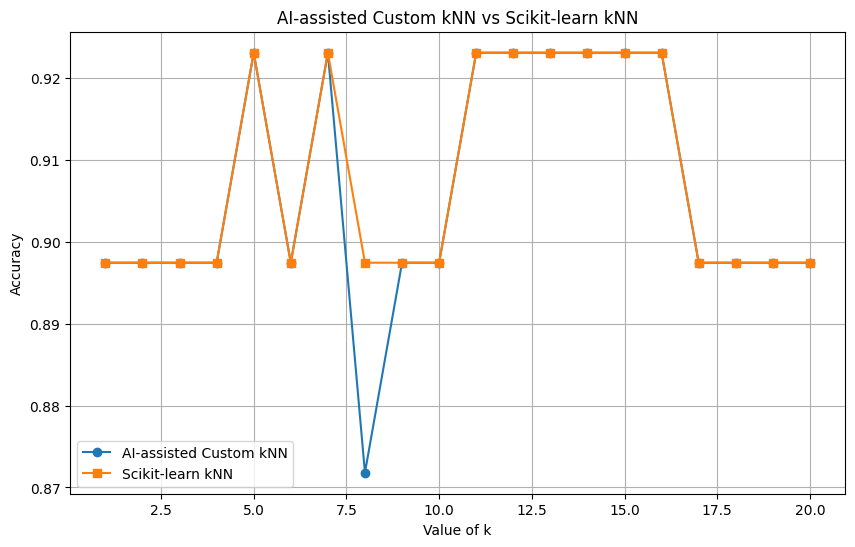

In [ ]:
# A8 - AI Tool Used: ChatGPT

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


def distance(a, b):

    return np.linalg.norm(
        np.array(a) - np.array(b)
    )


def find_neighbors(
    train_data,
    test_point
):

    train_data = np.array(
        train_data,
        dtype=float
    )

    test_point = np.array(
        test_point,
        dtype=float
    )

    labels = train_data[:, 0]

    features = train_data[:, 1:]

    distances = np.linalg.norm(
        features - test_point,
        axis=1
    )

    neighbors = np.column_stack(
        (distances, labels)
    ).tolist()

    return neighbors


def k_nearest_neighbors(
    neighbors,
    k
):

    neighbors = sorted(
        neighbors,
        key=lambda x: x[0]
    )

    return neighbors[:k]


def predict_class(
    neighbors
):

    labels = [
        neighbor[1]
        for neighbor in neighbors
    ]

    unique_labels = np.unique(
        labels
    )

    counts = {}

    for label in unique_labels:

        counts[label] = labels.count(
            label
        )

    highest_count = max(
        counts.values()
    )

    tied_labels = [
        label
        for label in counts
        if counts[label] == highest_count
    ]

    if len(tied_labels) == 1:

        return tied_labels[0]

    for neighbor in neighbors:

        if neighbor[1] in tied_labels:

            return neighbor[1]


def fit(
    X_train,
    y_train,
    k
):

    model = {
        "X_train": np.array(
            X_train,
            dtype=float
        ),

        "y_train": np.array(
            y_train
        ),

        "k": k
    }

    return model


def predict(
    model,
    X_test
):

    X_train = model["X_train"]

    y_train = model["y_train"]

    k = model["k"]

    predictions = []

    train_data = np.column_stack(
        (y_train, X_train)
    )

    for test_point in X_test:

        neighbors = find_neighbors(
            train_data,
            test_point
        )

        k_neighbors = k_nearest_neighbors(
            neighbors,
            k
        )

        prediction = predict_class(
            k_neighbors
        )

        predictions.append(
            prediction
        )

    return predictions


def score(
    model,
    X_test,
    y_test
):

    predictions = predict(
        model,
        X_test
    )

    predictions = np.array(
        predictions
    )

    y_test = np.array(
        y_test
    )

    return np.mean(
        predictions == y_test
    )


data_frame = pd.read_csv(
    "wine.csv"
)

data = data_frame.values.tolist()


selected_data = [
    row
    for row in data
    if row[0] == 1 or row[0] == 2
]


X = [
    row[1:]
    for row in selected_data
]

y = [
    row[0]
    for row in selected_data
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


k_values = list(
    range(1, 21)
)

custom_accuracies = []

package_accuracies = []


for k in k_values:

    custom_model = fit(
        X_train,
        y_train,
        k
    )

    custom_accuracy = score(
        custom_model,
        X_test,
        y_test
    )

    custom_accuracies.append(
        custom_accuracy
    )


    package_model = KNeighborsClassifier(
        n_neighbors=k
    )

    package_model.fit(
        X_train,
        y_train
    )

    package_accuracy = package_model.score(
        X_test,
        y_test
    )

    package_accuracies.append(
        package_accuracy
    )


print("A8 - CUSTOM kNN vs PACKAGE kNN")

print()

for i in range(
    len(k_values)
):

    print(
        "k =", k_values[i],
        "Custom =", custom_accuracies[i],
        "Package =", package_accuracies[i]
    )


plt.figure(
    figsize=(10, 6)
)

plt.plot(
    k_values,
    custom_accuracies,
    marker="o",
    label="AI-assisted Custom kNN"
)

plt.plot(
    k_values,
    package_accuracies,
    marker="s",
    label="Scikit-learn kNN"
)

plt.xlabel(
    "Value of k"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "AI-assisted Custom kNN vs Scikit-learn kNN"
)

plt.legend()

plt.grid(True)

plt.show()

A9 - WEIGHTED vs NORMAL kNN
k = 1 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 2 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 3 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 4 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 5 Normal kNN = 0.9230769230769231 Weighted kNN = 0.9230769230769231
k = 6 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 7 Normal kNN = 0.9230769230769231 Weighted kNN = 0.9230769230769231
k = 8 Normal kNN = 0.8717948717948718 Weighted kNN = 0.8717948717948718
k = 9 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 10 Normal kNN = 0.8974358974358975 Weighted kNN = 0.8974358974358975
k = 11 Normal kNN = 0.9230769230769231 Weighted kNN = 0.8974358974358975
k = 12 Normal kNN = 0.9230769230769231 Weighted kNN = 0.8974358974358975
k = 13 Normal kNN = 0.9230769230769231 Weighted kNN = 0.8974358974358975
k = 14 Normal kNN = 0.9230769230

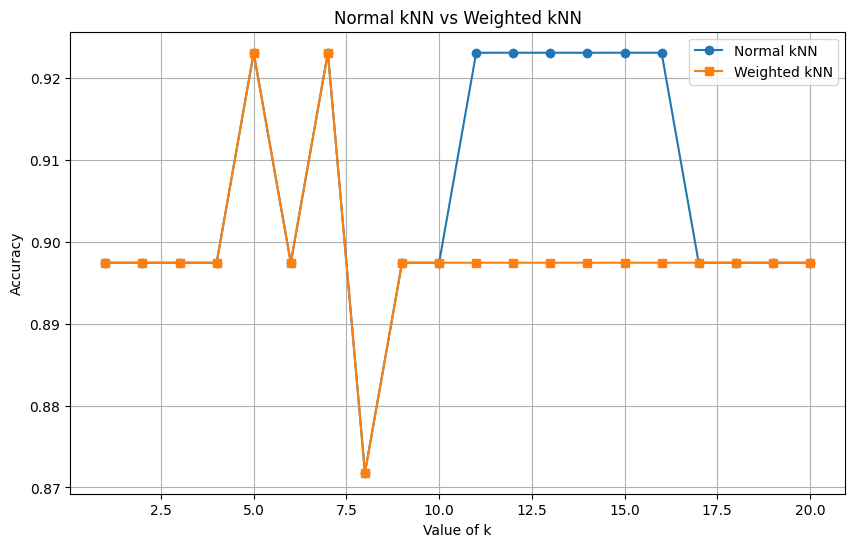

In [ ]:
# A9 - AI Tool Used: ChatGPT

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from collections import Counter


def distance(a, b):

    return np.linalg.norm(
        np.array(a) - np.array(b)
    )


def find_neighbors(
    train_data,
    test_point
):

    train_data = np.array(
        train_data,
        dtype=float
    )

    test_point = np.array(
        test_point,
        dtype=float
    )

    labels = train_data[:, 0]

    features = train_data[:, 1:]

    distances = np.linalg.norm(
        features - test_point,
        axis=1
    )

    neighbors = np.column_stack(
        (distances, labels)
    ).tolist()

    return neighbors


def k_nearest_neighbors(
    neighbors,
    k
):

    neighbors = sorted(
        neighbors,
        key=lambda x: x[0]
    )

    return neighbors[:k]


def normal_vote(
    neighbors
):

    labels = [
        neighbor[1]
        for neighbor in neighbors
    ]

    counts = Counter(labels)

    highest_count = max(
        counts.values()
    )

    tied_labels = [
        label
        for label in counts
        if counts[label] == highest_count
    ]

    if len(tied_labels) == 1:

        return tied_labels[0]

    for neighbor in neighbors:

        if neighbor[1] in tied_labels:

            return neighbor[1]


def weighted_vote(
    neighbors
):

    weights = {}

    for distance_value, label in neighbors:

        if distance_value == 0:

            weight = float("inf")

        else:

            weight = 1 / distance_value

        weights[label] = (
            weights.get(label, 0)
            + weight
        )

    highest_weight = max(
        weights.values()
    )

    tied_labels = [
        label
        for label in weights
        if weights[label] == highest_weight
    ]

    if len(tied_labels) == 1:

        return tied_labels[0]

    for neighbor in neighbors:

        if neighbor[1] in tied_labels:

            return neighbor[1]


def predict_normal(
    X_train,
    y_train,
    X_test,
    k
):

    predictions = []

    training_data = np.column_stack(
        (
            y_train,
            X_train
        )
    ).tolist()

    for test_point in X_test:

        neighbors = find_neighbors(
            training_data,
            test_point
        )

        k_neighbors = k_nearest_neighbors(
            neighbors,
            k
        )

        prediction = normal_vote(
            k_neighbors
        )

        predictions.append(
            prediction
        )

    return predictions


def predict_weighted(
    X_train,
    y_train,
    X_test,
    k
):

    predictions = []

    training_data = np.column_stack(
        (
            y_train,
            X_train
        )
    ).tolist()

    for test_point in X_test:

        neighbors = find_neighbors(
            training_data,
            test_point
        )

        k_neighbors = k_nearest_neighbors(
            neighbors,
            k
        )

        prediction = weighted_vote(
            k_neighbors
        )

        predictions.append(
            prediction
        )

    return predictions


def calculate_accuracy(
    predictions,
    actual_labels
):

    predictions = np.array(
        predictions
    )

    actual_labels = np.array(
        actual_labels
    )

    return np.mean(
        predictions == actual_labels
    )


data_frame = pd.read_csv(
    "wine.csv"
)

data = data_frame.values.tolist()


selected_data = [
    row
    for row in data
    if row[0] == 1 or row[0] == 2
]


X = [
    row[1:]
    for row in selected_data
]

y = [
    row[0]
    for row in selected_data
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)


k_values = list(
    range(1, 21)
)

normal_accuracies = []

weighted_accuracies = []


for k in k_values:

    normal_predictions = predict_normal(
        X_train,
        y_train,
        X_test,
        k
    )

    normal_accuracy = calculate_accuracy(
        normal_predictions,
        y_test
    )

    normal_accuracies.append(
        normal_accuracy
    )


    weighted_predictions = predict_weighted(
        X_train,
        y_train,
        X_test,
        k
    )

    weighted_accuracy = calculate_accuracy(
        weighted_predictions,
        y_test
    )

    weighted_accuracies.append(
        weighted_accuracy
    )


print("A9 - WEIGHTED vs NORMAL kNN")

for i in range(
    len(k_values)
):

    print(
        "k =", k_values[i],
        "Normal kNN =", normal_accuracies[i],
        "Weighted kNN =", weighted_accuracies[i]
    )


plt.figure(
    figsize=(10, 6)
)

plt.plot(
    k_values,
    normal_accuracies,
    marker="o",
    label="Normal kNN"
)

plt.plot(
    k_values,
    weighted_accuracies,
    marker="s",
    label="Weighted kNN"
)

plt.xlabel(
    "Value of k"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Normal kNN vs Weighted kNN"
)

plt.legend()

plt.grid(True)

plt.show()